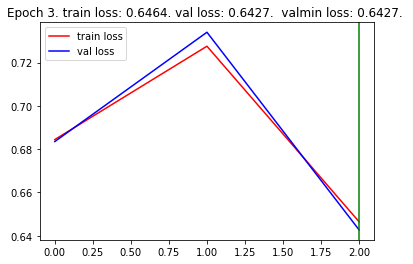

Epoch Duration: 24.470913410186768's
Experiment name: seg_lung_unet_loss_dice_XXXXXXX


KeyboardInterrupt: 

In [1]:
import os
from pathlib import Path
import h5py
from IPython.display import clear_output
import matplotlib.pyplot as plt
%matplotlib inline

import cv2, time
import random
import skimage
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as tr
from sklearn.model_selection import KFold
from skimage import morphology
from IPython.display import clear_output
# import pandas as pd

from utils import *

from model.segtrainer import SegTrainer
from model.seginferencer import SegInferencer
from model.losses import losser

# you can write your own func of data_preprocess begin at training
def data_preprocess(in_dir: Path, out_dir: Path, suffix: str = "png", labels_class_num: int = 2) -> Tuple:
    """
        Prepare the data for training
        :param in_dir:  the input directory of origin data 
        :param out_dir: the output directory of processed data
        :param suffix:  the suffix of raw image file
        :param labels_class_num: the number of class in label
        :return: (mean, std, num) of raw image, which is used for normalization
    """
    
    # the 100MB limit of github ask me can not load data_backup.zip
    # unzip the data_backup.zip file
    # zip_pth = Path(in_dir.parent, "data_backup.zip")
    # unzip_file(zip_pth, out_dir.parent)
    
    # imgs_inpath   = Path(in_dir, "images")
    # labels_inpath = Path(in_dir, "labels")
    
    zip_pth = Path(in_dir.parent, "data_experiment.zip")
    unzip_file(zip_pth, out_dir.parent)
    
    imgs_outpath = Path(out_dir, "images")
    labels_outpath = Path(out_dir, "labels")
    imgs_outpath.mkdir(parents=True, exist_ok=True) 
    labels_outpath.mkdir(parents=True, exist_ok=True)
    
    print("File Converting...")
    print("The image's path is {}".format(str(imgs_outpath  )))
    print("The label's path is {}".format(str(labels_outpath)))
    
    # imgs_path_list = list(imgs_inpath.glob("*.tif"))
    imgs_path_list = list(imgs_outpath.glob("*.png"))
    
    for img_idx, img_path in enumerate(imgs_path_list):
        img   = io.imread(str(img_path))
        # img   = (img  - img.min()) * 255.0 / (img.max() - img.min()) # normalization to [0,1]
        # label = io.imread(str(Path(labels_inpath, img_path.name)))
        # io.imsave(str(Path(imgs_outpath, str(img_path.name).replace(".tif", '.' + suffix))), img.astype(np.uint8))
        # np.save(str(Path(labels_outpath, str(img_path.name).replace(".tif", '.npy'))), (label/255).astype(np.uint8)) 
        
        label = np.load(str(Path(labels_outpath, str(img_path.name).replace(".png", '.npy'))))
    
        if img_idx == 0:
            plt.figure(figsize=(10, 10))
            plt.subplot(1, 2, 1), plt.imshow(img,   cmap="gray"), plt.title("image"), plt.axis("off")
            plt.subplot(1, 2, 2), plt.imshow(label, cmap="gray"), plt.title("label"), plt.axis("off")
            plt.show()                         
    
    # it is useful for your data preprocessing function
    print("Generating weight map...")
    weights_func = ["bcw"]
    losser.prepare_weight_map(labels_outpath, out_dir, weights_func, labels_class_num)  
    print("Generated weight map in {}".format(str(out_dir)))
    
    mean, std, num = count_mean_and_std(imgs_outpath, suffix)
    print("mean = {}, std ={} and image num = {}".format(mean, std, num))
    print("Data Preprocess has done")
    clear_output(True)
    
    return mean, std, num


# you can define your own data_postprocess in the step of inference
def data_postprocess(in_img: np.ndarray) -> np.ndarray:
    """
        post processing data after inference before evaluation
        :param in_img:
        :return out_img:
    """
    out_img = morphology.remove_small_holes(in_img  == 0, 0.01 * in_img.shape[0] * in_img.shape[1])
    out_img = np.where(out_img, 0, 1)
    out_img = morphology.remove_small_holes(out_img == 1, 0.01 * in_img.shape[0] * in_img.shape[1])
    out_img = np.where(out_img, 1, 0)
    return out_img


def train(data_name: str, data_bk_dir: Path, data_dir: Path, params_path: Path, custom_desc: str) -> str:
    """
        Train netowrk
        :param data_name:
        :param data_bk_dir:  the input directory of origin data 
        :param data_dir:     the output directory of processed data
        :param params_path:  the path of certain experimental parameters
        :param custom_desc:  the custom description which add last in the experiment_name, you can define it
        :return: experiment_name, which is used to record all the parameter in training
    """
    
    # load params of experiment
    params = ParamsYml().load_params(params_path)
    
    # data preprocess
    mean, std, num = data_preprocess(data_bk_dir, data_dir, suffix = params["data"]["imgs_suffix"], 
                                     labels_class_num = params["data"]["labels_class_num"])
    
    
    # you can direct assign values in here in order to avoid repeat execution of data_preprocess
    # for lung,  mean=0.36717652957275027, std =0.20829624788193762 and image num = 267
    
    params["data"]["name"]      = data_name
    params["data"]["dir"]       = str(data_dir)
    params["data"]["imgs_mean"] = 0.367176529572750
    params["data"]["imgs_std"]  = 0.208296247881937
    params["data"]["imgs_num"]  = 267
    
    
    experiment_name = set_experiment_name(params, custom_desc)
    
    experiment_dir  = Path(Path.cwd(), "experiment", experiment_name)
    experiment_dir.mkdir(parents=True, exist_ok=True)
    print("Parameters will be saved in {}".format(str(experiment_dir)))
    
    seg_trainer = SegTrainer(params, experiment_dir, data_postprocess)
    
    # Training
    seg_trainer.start_training()
    
    return experiment_name


def inference(experiment_name: str) -> None:
    """
        inference data according to previous training record
        :param experiment_name: which is used to record all the parameter in training
    """
    # Wether to analyse all data or only test dataset 
    is_test_all = True
    seg_trainer = SegInferencer(experiment_name, is_test_all, data_postprocess)
    seg_trainer.start_inference()


if __name__ == '__main__':
    
    data_name   = "lung"
    data_bk_dir = Path(Path.cwd(), "data", data_name, "data_backup")
    data_dir    = Path(Path.cwd(), "data", data_name, "data_experiment")
    params_path = Path(Path.cwd(), "lung_dice.yml")
    custom_desc = "XXXXXXX"          # you can add your description in here
    
    # Tranining
    experiment_name = train(data_name, data_bk_dir, data_dir, params_path, custom_desc)
    
    
    # Inference
    experiment_name = "seg_lung_unet_loss_dice_XXXXXXX"
    inference(experiment_name)